In [ ]:
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt

from collections import Counter
from sklearn.svm import SVC, OneClassSVM
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV

from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef

from scipy.stats import randint, uniform, loguniform

In [2]:
df = pd.read_csv(r"data/company_bankruptcy.csv")
display(df.sample(5).reset_index(drop=True))
Counter(df.dtypes.values)

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,0,0.481792,0.540667,0.536324,0.605904,0.605904,0.998984,0.797396,0.809323,0.303504,...,0.798556,0.000864,0.623740,0.605901,0.840212,0.277532,0.028586,0.568330,1,0.044186
1,0,0.643007,0.690526,0.673484,0.606862,0.606862,0.999057,0.797644,0.809506,0.303786,...,0.881318,0.003145,0.623816,0.606861,0.846304,0.278641,0.026793,0.565168,1,0.034678
2,0,0.494857,0.556640,0.549815,0.623942,0.623813,0.999025,0.797460,0.809380,0.303529,...,0.810739,0.000834,0.623821,0.623941,0.840922,0.276660,0.026794,0.565173,1,0.059145
3,0,0.474285,0.545573,0.529953,0.601385,0.601385,0.998999,0.797454,0.809401,0.303574,...,0.804862,0.000693,0.624061,0.601384,0.840477,0.275128,0.026796,0.565182,1,0.226769
4,0,0.473212,0.551079,0.527384,0.601515,0.601508,0.999020,0.797441,0.809367,0.303508,...,0.807007,0.023545,0.623781,0.601513,0.840621,0.275637,0.026837,0.565368,1,0.111493


Counter({dtype('float64'): 93, dtype('int64'): 3})

In [3]:
[x for x in df.columns if df[x].isnull().sum() > 0]

[]

In [4]:
pd.set_option('display.max_columns', None)
df.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,0.781381,1.995347e+09,1.950427e+09,0.467431,1.644801e+07,0.11

<Axes: >

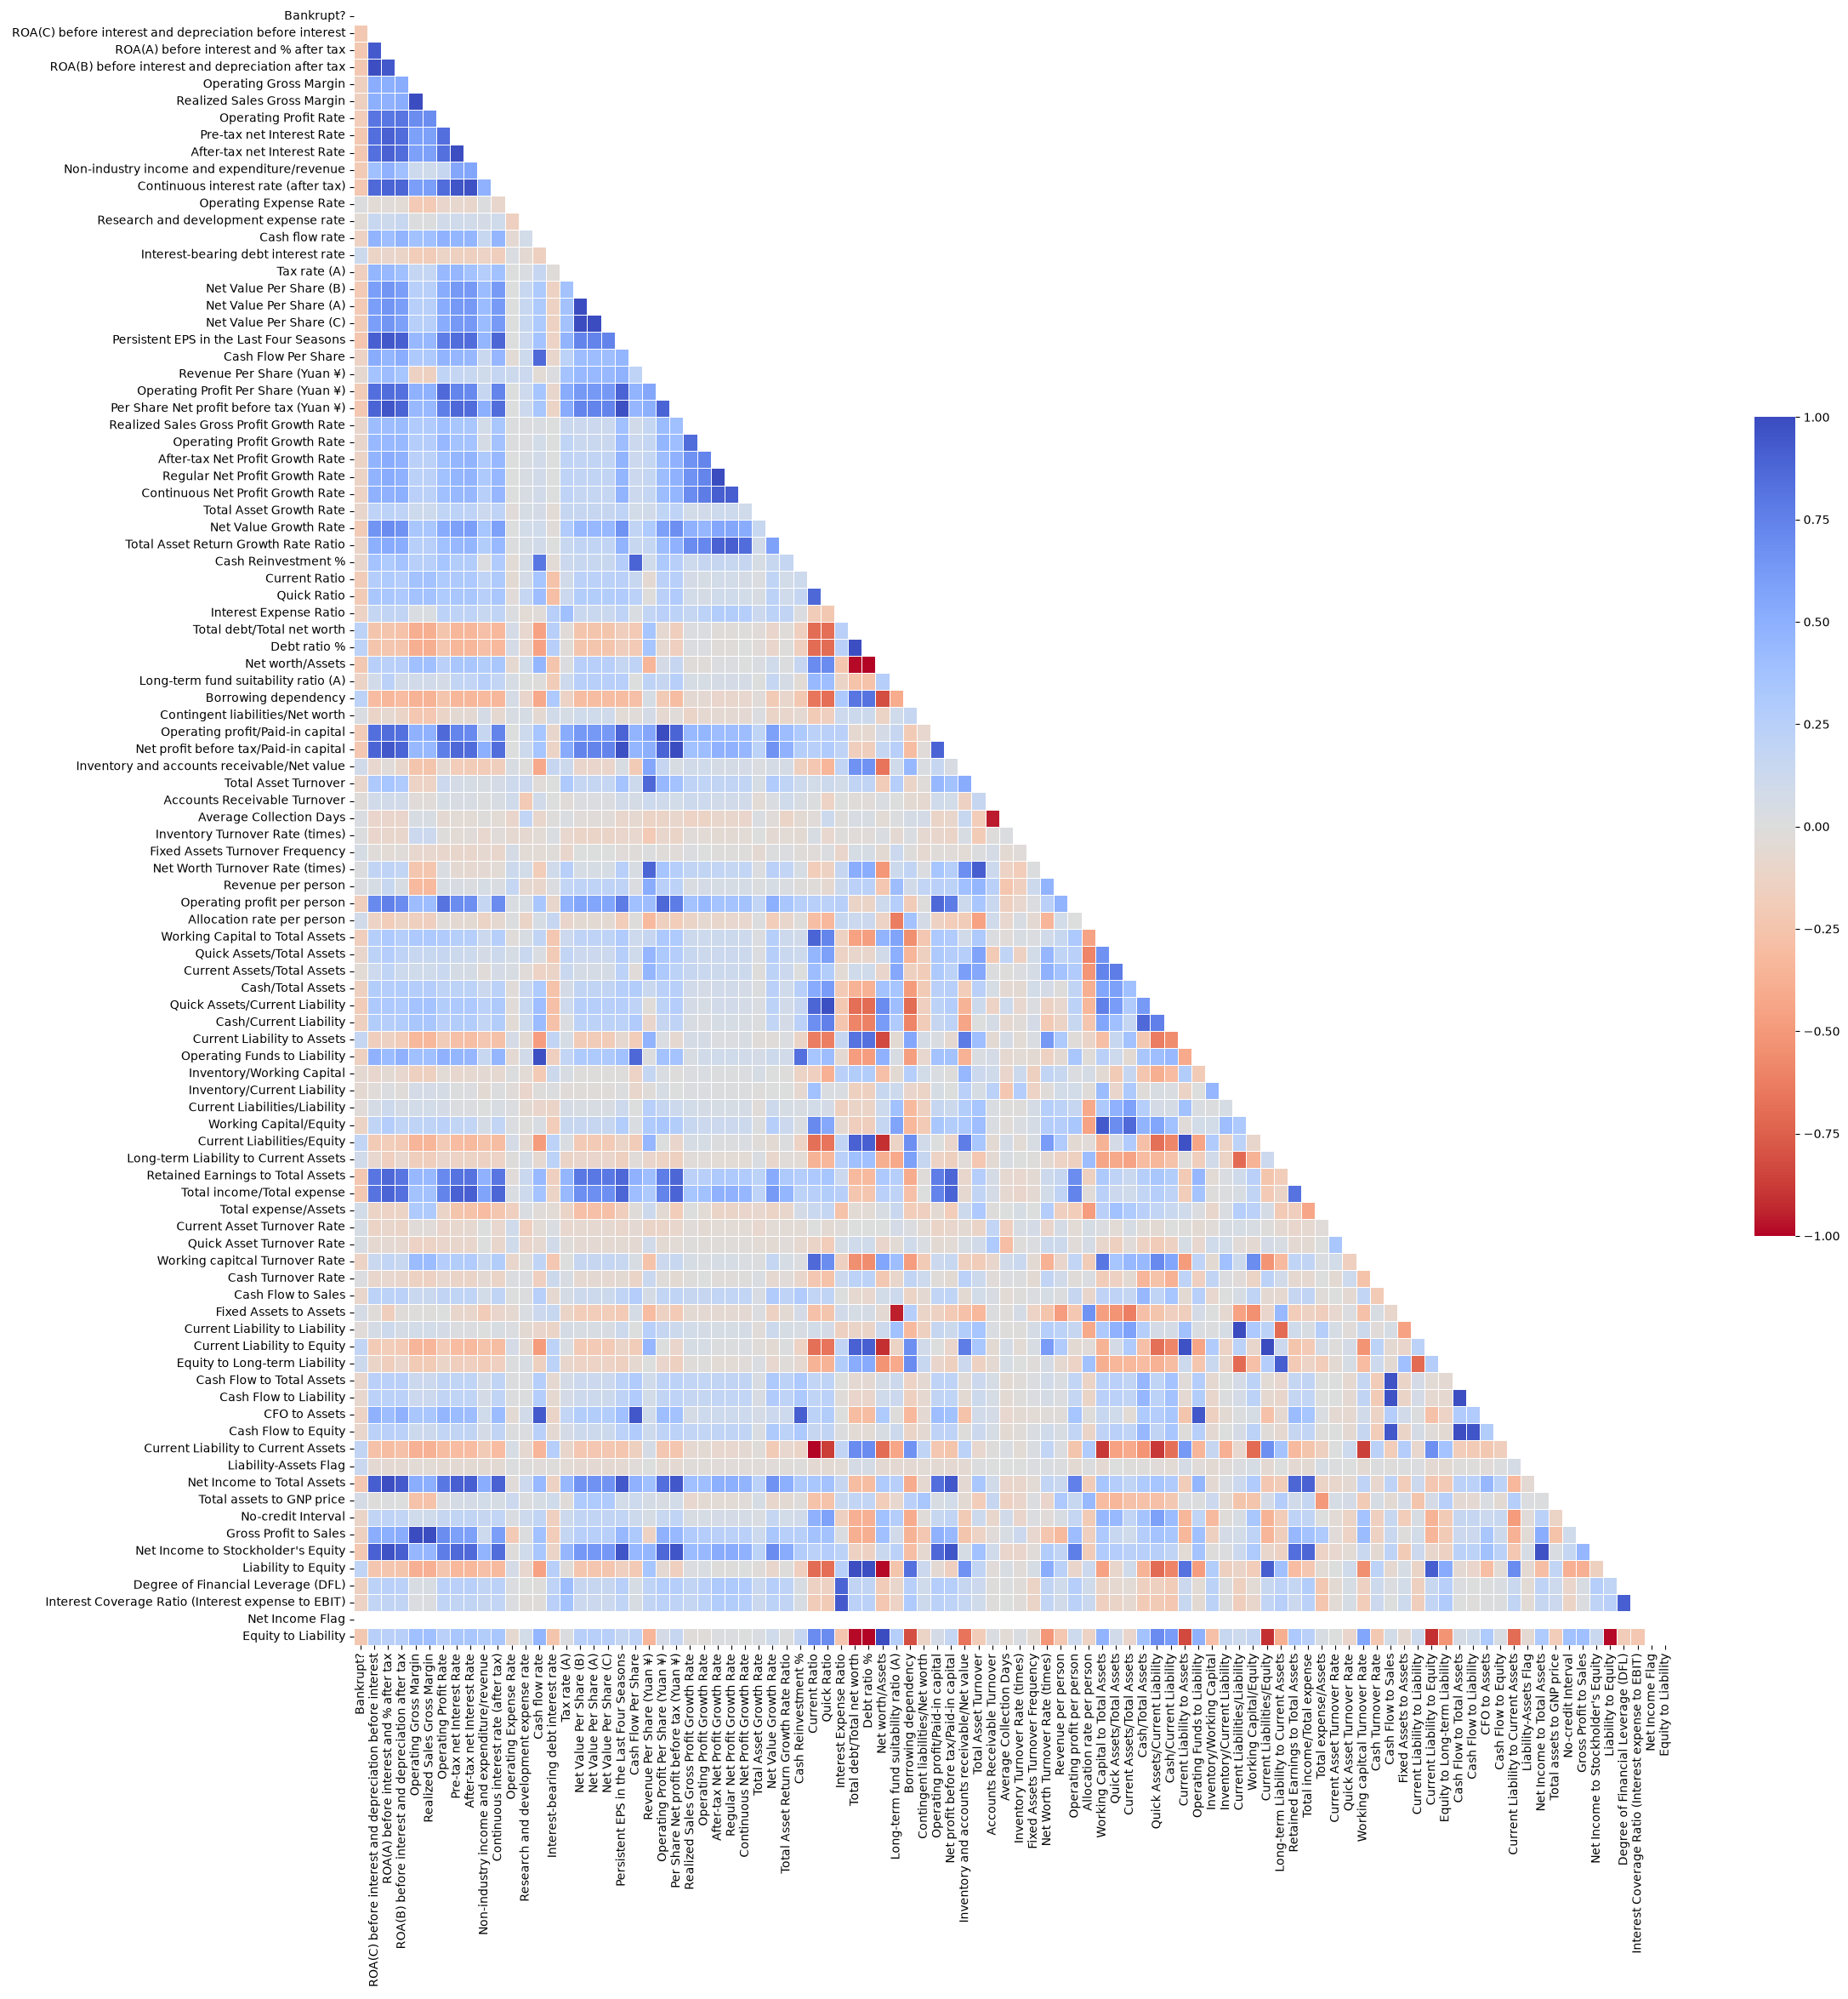

In [5]:
fig, ax = plt.subplots(figsize=(25, 25))
mat = df.corr('spearman').round(2) # spearman was used because this dataset has to much outliers
mask = np.triu(np.ones_like(mat, dtype=bool))
sns.heatmap(mat, mask=mask, cmap='coolwarm_r', ax=ax,  center=0, cbar_kws={"shrink": .5}, linewidths=0.5)

In [6]:
print(df[' Net Income Flag'].value_counts()) # this column has no statistcal influence so it will be removed as it's obvious in the heatmap
del df[' Net Income Flag']

 Net Income Flag
1    6819
Name: count, dtype: int64


In [7]:
# i have noticed that all columns start with ' ' so i will handle it
df.columns = df.columns.str.strip()

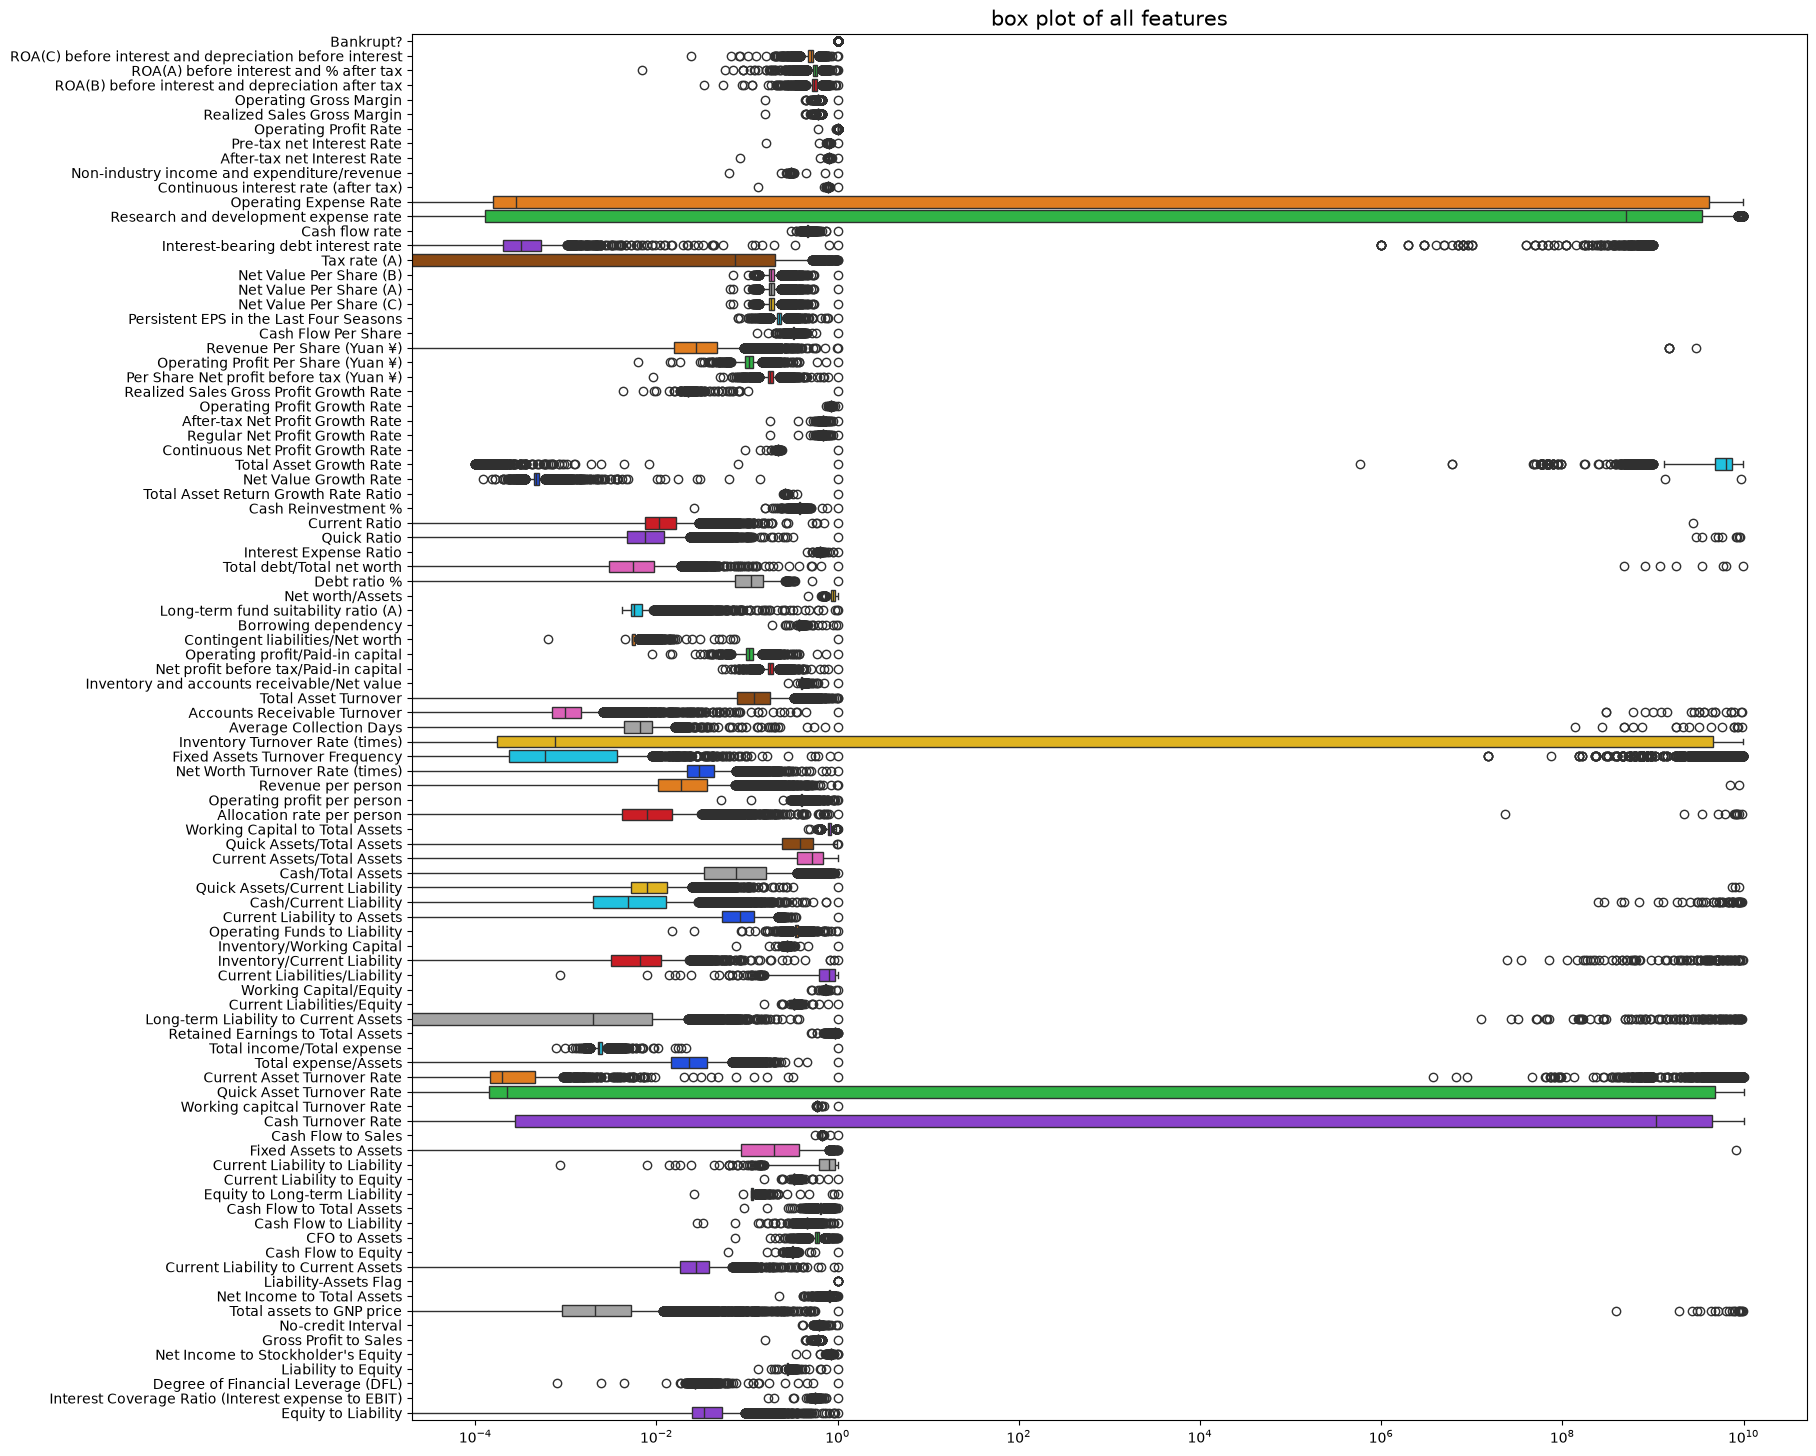

In [8]:
plt.figure(figsize=(18,18))
ax = sns.boxplot(data=df, orient='h', palette='bright')
ax.set_title('box plot of all features', fontsize=15, color='black')
ax.set(xscale='log')
plt.show()

In [9]:
outliers_df = pd.DataFrame(index=['upper_outliers', 'lower_outliers'])
for col in df.columns:
    q3 = np.percentile(df[col], 75)
    q1 = np.percentile(df[col], 25)
    iqr = (q3 - q1) * 1.5 
    upper_band = q3 + iqr
    lower_band = q1 - iqr
    temp_df = pd.DataFrame(columns=[col], index=['upper_outliers', 'lower_outliers'], data=[Counter(df[col] > upper_band)[True], Counter(df[col] < lower_band)[True]])
    outliers_df = pd.concat([outliers_df, temp_df], axis=1)
outliers_df

# when i tried to delete outliers i only has less than 250 sample with no bankrupcty cases 

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
upper_outliers,220,197,232,191,253,252,282,235,262,537,245,0,182,431,396,120,419,420,421,367,303,478,380,375,620,596,491,492,510,0,656,431,242,589,591,883,407,30,0,809,313,939,385,356,417,351,659,193,0,1418,513,729,612,693,49,2,0,496,596,728,95,494,634,426,0,30,472,620,136,389,372,1399,0,453,0,582,62,0,472,403,532,721,141,485,276,8,171,797,512,253,112,396,944,873,549
lower_outliers,0,194,329,241,67,66,434,538,605,557,561,0,0,145,0,0,38,44,44,141,229,0,62,136,194,412,542,538,532,1381,136,243,375,0,0,479,0,0,30,1,8,3,61,120,4,0,0,0,0,0,0,0,264,0,26,0,0,0,0,0,0,163,310,0,40,123,8,0,497,74,0,0,0,125,0,470,0,40,8,3,346,491,201,342,0,0,390,0,627,67,459,8,559,548,0


<Axes: title={'center': 'Bankruptcy cases percentage'}>

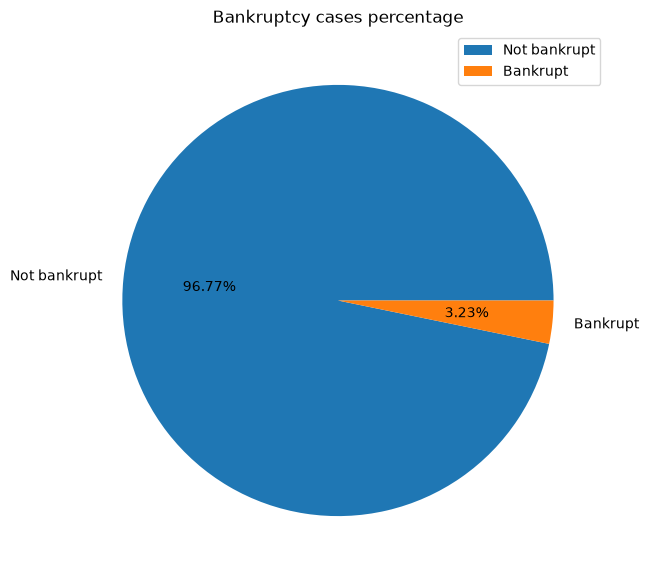

In [10]:
value_counts = df["Bankrupt?"].value_counts()
value_counts.index = value_counts.index.map({0: "Not bankrupt", 1: "Bankrupt"})

value_counts.plot(
    kind="pie",
    title="Bankruptcy cases percentage",
    autopct="%1.2f%%",
    legend=True,
    figsize=(7,7)
)
# this data set is very imbalanced 
# random forset and decision tree need balanced dataset i will use special balanced dataset to train them but imbalanced dataset for and hyperparams tuning testing 
# i will use OneClassSVM instead of SVC because it handle imbalanced dataset better
# for the other models i will use the same imbalanced dataset and more method to evalute the predict values

In [11]:
y = df['Bankrupt?']
x = df[df.columns[1:]]

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=74)
rb_scaler = MinMaxScaler()
x_train = rb_scaler.fit_transform(x_train)
x_test = rb_scaler.transform(x_test)

In [ ]:
true_220_sample_bankrept = df[df['Bankrupt?']==1]
false_220_sample_bankrept = df[df['Bankrupt?']==0].sample(frac=1)[:220]

balanced_df = pd.concat([true_220_sample_bankrept, false_220_sample_bankrept], axis=0).sample(frac=1)

yb = balanced_df['Bankrupt?']
xb = balanced_df[df.columns[1:]]

xb_train, xb_test, yb_train, yb_test = train_test_split(xb, yb, test_size=0.25, random_state=74)
rb_scaler = MinMaxScaler()
xb_train = rb_scaler.fit_transform(xb_train)
xb_test = rb_scaler.transform(xb_test)

In [ ]:
# evaluates a fitted model on the test set:
# prints the classification report + MCC and returns precision / recall / f1 / mcc
# as a dict (collected later in the before/after tuning summary)
def evaluate(name, model):
    y_pred = model.predict(xb_test)

    print(f"--- {name} ---")
    print(classification_report(yb_test, y_pred, zero_division=1))
    print("MCC:", round(matthews_corrcoef(yb_test, y_pred), 4))

    return {
        "precision": precision_score(yb_test, y_pred, zero_division=1),
        "recall": recall_score(yb_test, y_pred, zero_division=1),
        "f1": f1_score(yb_test, y_pred, zero_division=1),
        "mcc": matthews_corrcoef(yb_test, y_pred),
    }

In [ ]:
svm_model = SVC(random_state=74)
svm_model = svm_model.fit(xb_train, yb_train)
svm_default_metrics = evaluate("Default SVC", svm_model)

# GridSearchCV: small discrete kernel/C/gamma space -> exhaustive grid
svm_param_grid = [
    {   # RBF kernel
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto", 0.001, 0.01, 0.1],
    },
    {   # Linear kernel
        "kernel": ["linear"],
        "C": [0.01, 0.1, 1, 10, 100],
    },
    {   # Polynomial kernel
        "kernel": ["poly"],
        "C": [1, 10, 100],
        "degree": [2, 3],
        "gamma": ["scale", 0.01],
        "coef0": [0.0, 1.0],
    },
    {   # Sigmoid kernel
        "kernel": ["sigmoid"],
        "C": [1, 10],
        "gamma": ["scale", 0.01],
        "coef0": [0.0, 1.0],
    },
]

# param space product: 57 (20 rbf + 5 linear + 24 poly + 8 sigmoid) x 10 cv folds = 570 fits
svm_search = GridSearchCV(
    estimator=SVC(random_state=74),
    param_grid=svm_param_grid,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
)
svm_search.fit(xb_train, yb_train)
svm_best_params = svm_search.best_params_

svm_tuned = svm_search.best_estimator_
svm_tuned_metrics = evaluate("Tuned SVC", svm_tuned)

In [ ]:
knn_model = KNeighborsClassifier()
knn_model = knn_model.fit(xb_train, yb_train)
knn_default_metrics = evaluate("Default KNN", knn_model)

# GridSearchCV: small discrete space (k / weights / metric) -> exhaustive grid
knn_param_grid = [
    {
        "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan", "cosine"],
    },
    {
        "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41],
        "weights": ["uniform", "distance"],
        "metric": ["minkowski"],
        "p": [1, 2, 3],
    },
]

# param space product: 108 (54 metric grid + 54 minkowski p) x 10 cv folds = 1080 fits
knn_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
)
knn_search.fit(xb_train, yb_train)
knn_best_params = knn_search.best_params_

knn_tuned = knn_search.best_estimator_
knn_tuned_metrics = evaluate("Tuned KNN", knn_tuned)

In [ ]:
dt_model = DecisionTreeClassifier()
dt_model = dt_model.fit(xb_train, yb_train)
dt_default_metrics = evaluate("Default Decision Tree", dt_model)

# GridSearchCV: small discrete set of tree knobs -> exhaustive grid
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "ccp_alpha": [0.0, 0.01],
}

# param space product: 180 (2 criterion x 5 max_depth x 3 min_samples_split x 3 min_samples_leaf x 2 ccp_alpha) x 10 cv folds = 1800 fits
dt_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=74),
    param_grid=dt_param_grid,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
)
dt_search.fit(xb_train, yb_train)
dt_best_params = dt_search.best_params_

dt_tuned = dt_search.best_estimator_
dt_tuned_metrics = evaluate("Tuned Decision Tree", dt_tuned)

In [ ]:
rf_model = RandomForestClassifier()
rf_model = rf_model.fit(xb_train, yb_train)
rf_default_metrics = evaluate("Default Random Forest", rf_model)

# RandomizedSearchCV: many hyperparameters with wide continuous ranges -> random search
rf_param_dist = {
    "n_estimators": randint(100, 600),
    "max_depth": [None, 5, 10, 20, 30],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 6),
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False],
    "class_weight": [None, "balanced"],
}

# param space product: 1,350,000 (500 n_estimators x 5 max_depth x 9 min_samples_split x 5 min_samples_leaf x 3 max_features x 2 bootstrap x 2 class_weight) -> n_iter=40 samples ~0.003% of it, raise n_iter if you want wider coverage
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=74),
    param_distributions=rf_param_dist,
    n_iter=40,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
    random_state=74,
)
rf_search.fit(xb_train, yb_train)
rf_best_params = rf_search.best_params_

rf_tuned = rf_search.best_estimator_
rf_tuned_metrics = evaluate("Tuned Random Forest", rf_tuned)

In [ ]:
lr_model = LogisticRegression(max_iter=10000)
lr_model = lr_model.fit(xb_train, yb_train)
lr_default_metrics = evaluate("Default Logistic Regression", lr_model)

# GridSearchCV: few discrete penalty/C/solver combos -> exhaustive grid
lr_param_grid = [
    {
        "penalty": ["l2"],
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "solver": ["lbfgs"],
    },
    {
        "penalty": ["l1", "l2"],
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "solver": ["liblinear"],
    },
]

# param space product: 18 (6 lbfgs-l2 + 12 liblinear-l1/l2) x 10 cv folds = 180 fits
lr_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=10000),
    param_grid=lr_param_grid,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
)
lr_search.fit(xb_train, yb_train)
lr_best_params = lr_search.best_params_

lr_tuned = lr_search.best_estimator_
lr_tuned_metrics = evaluate("Tuned Logistic Regression", lr_tuned)

In [ ]:
nb_model = GaussianNB()
nb_model = nb_model.fit(xb_train, yb_train)
nb_default_metrics = evaluate("Default Naive Bayes", nb_model)

# RandomizedSearchCV: var_smoothing is a single continuous log-uniform parameter -> random search
nb_param_dist = {
    "var_smoothing": loguniform(1e-11, 1e-1),
}

# param space product: unbounded (var_smoothing is one continuous log-uniform range) -> any n_iter is just a sample (currently 30)
nb_search = RandomizedSearchCV(
    estimator=GaussianNB(),
    param_distributions=nb_param_dist,
    n_iter=30,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
    random_state=74,
)
nb_search.fit(xb_train, yb_train)
nb_best_params = nb_search.best_params_

nb_tuned = nb_search.best_estimator_
nb_tuned_metrics = evaluate("Tuned Naive Bayes", nb_tuned)

In [ ]:
gb_model = GradientBoostingClassifier()
gb_model = gb_model.fit(xb_train, yb_train)
gb_default_metrics = evaluate("Default Gradient Boosting", gb_model)

# RandomizedSearchCV: large continuous space (lr / trees / subsample) -> random search
gb_param_dist = {
    "n_estimators": randint(50, 500),
    "learning_rate": loguniform(0.01, 0.3),
    "max_depth": randint(2, 6),
    "subsample": uniform(0.6, 0.4),
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 6),
}

# param space product: 81,000 discrete (450 n_estimators x 4 max_depth x 9 min_samples_split x 5 min_samples_leaf) x 2 continuous dims (learning_rate, subsample) -> unbounded; n_iter=40 is a sample, raise it if you want
gb_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=74),
    param_distributions=gb_param_dist,
    n_iter=40,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
    random_state=74,
)
gb_search.fit(xb_train, yb_train)
gb_best_params = gb_search.best_params_

gb_tuned = gb_search.best_estimator_
gb_tuned_metrics = evaluate("Tuned Gradient Boosting", gb_tuned)

In [ ]:
mlp_model = MLPClassifier(hidden_layer_sizes=(400,400), activation="tanh", solver='lbfgs')
mlp_model = mlp_model.fit(xb_train, yb_train)
mlp_default_metrics = evaluate("Default MLP", mlp_model)

# RandomizedSearchCV: huge architecture/regularization space -> random search
mlp_param_dist = {
    "hidden_layer_sizes": [(50,), (100,), (200,), (400,), (50, 50), (100, 100), (400, 400)],
    "activation": ["tanh", "relu", "logistic"],
    "solver": ["adam", "lbfgs"],
    "alpha": loguniform(1e-5, 1e-1),
    "learning_rate_init": loguniform(1e-4, 1e-1),
}

# param space product: 42 discrete (7 hidden_layer_sizes x 3 activation x 2 solver) x 2 continuous dims (alpha, learning_rate_init) -> unbounded; n_iter=30 is a sample, raise it if you want
mlp_search = RandomizedSearchCV(
    estimator=MLPClassifier(max_iter=500, random_state=74),
    param_distributions=mlp_param_dist,
    n_iter=30,
    scoring="matthews_corrcoef",
    cv=10,
    n_jobs=-1,
    verbose=1,
    random_state=74,
)
mlp_search.fit(xb_train, yb_train)
mlp_best_params = mlp_search.best_params_

mlp_tuned = mlp_search.best_estimator_
mlp_tuned_metrics = evaluate("Tuned MLP", mlp_tuned)

In [ ]:
# building classification neural network with pytorch 

import torch 
from torch import nn 
from torch.utils.data import DataLoader, TensorDataset

class ClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(94, 94*2)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(94*2, 94*4)
        self.tanh1 = nn.Tanh()

        self.fc3 = nn.Linear(94*4, 94*2)
        self.relu2 = nn.ReLU()

        self.fc4 = nn.Linear(94*2, 94)
        self.tanh2 = nn.Tanh()

        self.output = nn.Linear(94, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu1(self.fc1(x))
        x = self.tanh1(self.fc2(x))
        x = self.relu2(self.fc3(x))
        x = self.tanh2(self.fc4(x))

        return self.sigmoid(self.output(x))

# converting the data to tensors
xb_train_tensor = torch.tensor(np.array(xb_train), dtype=torch.float32)
yb_train_tensor = torch.tensor(np.array(yb_train), dtype=torch.float32).reshape(-1, 1)

xb_test_tensor = torch.tensor(np.array(xb_test), dtype=torch.float32)
yb_test_tensor = torch.tensor(np.array(yb_test), dtype=torch.float32).reshape(-1, 1)

train_dataset = TensorDataset(
    xb_train_tensor, yb_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

model = ClassificationModel()

criterion = nn.BCELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.005,
)

epoch_count = []
test_losses = []
train_loss = []


for epoch in range(5000):
    model.train()

    for x, y in train_loader:

        y_pred = model(x)
        loss = criterion(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch % 10 == 0:
        model.eval()
        with torch.inference_mode():
            y_pred_test = model(xb_test_tensor)
            test_loss = criterion(y_pred_test, yb_test_tensor) 
        test_losses.append(test_loss)       
        epoch_count.append(epoch)
        train_loss.append(loss)

Index(['Not bankrupt', 'Bankrupt'], dtype='str', name='Bankrupt?')

In [ ]:
plt.figure(figsize=(20, 6))

plt.plot(epoch_count, train_loss, label="Training Loss")
plt.plot(epoch_count, test_losses, label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Testing Loss")

plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

In [ ]:
# best hyperparameters found by the searches (printed once, here)
for name, best_params in [
    ("SVC",               svm_best_params),
    ("KNN",               knn_best_params),
    ("Decision Tree",     dt_best_params),
    ("Random Forest",     rf_best_params),
    ("Logistic Regression", lr_best_params),
    ("Naive Bayes",       nb_best_params),
    ("Gradient Boosting", gb_best_params),
    ("MLP",               mlp_best_params),
]:
    print(f"{name}: {best_params}")

print()

# before (default) vs after (tuned) metrics for every model
metrics_rows = {}
for name, default_metrics, tuned_metrics in [
    ("SVC",               svm_default_metrics, svm_tuned_metrics),
    ("KNN",               knn_default_metrics, knn_tuned_metrics),
    ("Decision Tree",     dt_default_metrics,  dt_tuned_metrics),
    ("Random Forest",     rf_default_metrics,  rf_tuned_metrics),
    ("Logistic Regression", lr_default_metrics, lr_tuned_metrics),
    ("Naive Bayes",       nb_default_metrics,  nb_tuned_metrics),
    ("Gradient Boosting", gb_default_metrics,  gb_tuned_metrics),
    ("MLP",               mlp_default_metrics, mlp_tuned_metrics),
]:
    metrics_rows[(name, "default")] = default_metrics
    metrics_rows[(name, "tuned")] = tuned_metrics

metrics_df = pd.DataFrame(metrics_rows).T
metrics_df.columns = ["Precision", "Recall", "F1", "MCC"]
metrics_df.index.names = ["Model", "Tuning"]
metrics_df.round(4)